# 10 · Explainability: what drives the models, globally and locally (Milestone 12)

**The questions:**
1. What drives expected flood loss cost **across Virginia** (global explanations)?
2. **Why** does one group of buildings or one county get the number it gets (local explanations)?
3. Do the production GLM and the XGBoost challenger tell the same story?

*Area-level analysis of aggregated public data: every number describes the average for a group of similar insured buildings, never a prediction for an individual property.*

**Models:**
- **Production (Milestone 11):** the **hybrid GLM** (Poisson frequency × Gamma severity, three interactions, loads, Bühlmann–Straub county factor), `models/production_model.json`. It's a GLM, so its global explanation is its relativity table. For a like-for-like comparison we also compute its exact SHAP values.
- **Benchmark:** the three XGBoost models from Milestone 10 (`models/xgb_*_all`, all 16 years), explained with **SHAP**.

**Code:**
- `src/global_explain.py`: GLM SHAP and XGBoost TreeSHAP helpers.
- `src/explain.py`: local explanations and the app data.

Both have self-tests.

**Lighter-approach rule** (pre-stated): SHAP values for every row (about 3 minutes); beeswarms on 5,000 rows sampled in proportion to exposure; interaction values on 3,000 rows.

In [1]:
import json
import math
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "src" / "models"))
import explain as E
import global_explain as G
from models import xgb_models as X
from models import production

warnings.filterwarnings("ignore")
FIG, REP = ROOT / "reports" / "figures", ROOT / "reports"
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70)

# Palette: slots 1-3 of the validated reference palette (dataviz skill), neutral inks, blue ramp for magnitude.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
CAT = [BLUE, ORANGE, AQUA, YELLOW]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
NAMES = {**E.LABELS, "coastal_tidal": "Tidewater", "county_group": "County group",
         "county": "County factor", "geography": "Geography (county)", "post_firm": "Post-FIRM"}
import matplotlib.ticker as mticker
TICKS = [0.1, 0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.25, 1.5, 2, 3, 4, 6]
def mult_axis(ax, axis="x"):
    """Log axis labelled as multipliers (x0.5, x1, x2) instead of scientific notation."""
    a = ax.xaxis if axis == "x" else ax.yaxis
    lo, hi = (ax.get_xlim() if axis == "x" else ax.get_ylim())
    t = [v for v in TICKS if lo <= v <= hi]
    a.set_major_locator(mticker.FixedLocator(t)); a.set_minor_locator(mticker.NullLocator())
    a.set_major_formatter(mticker.FixedFormatter([f"x{v:g}" for v in t]))

## 0. Data and models
- **P** = the Virginia insured portfolio 2010–2025: one row per building type × county, weighted by policy-years (exposure). It's the population for frequency and pure-premium explanations.
- **CL** = the 9,545 Virginia paid claims, the population for severity (claim-size) explanations, because that's what the severity models are fitted on.

In [2]:
EX = E.load()                     # rating tables, Virginia portfolio, county summary (committed files)
T, PM = EX.t, EX.model            # PM = production.ProductionModel
cells = pd.read_parquet(X.CELLS_PATH)
va = cells[cells["county"].astype(str).str.startswith("51") & cells["exposure_matched"] & (cells["exposure"] > 0)]
KEYS = X.BUILDING_FEATURES + ["coastal_tidal", "county_group", "county"]
P = va.groupby(KEYS, observed=True)[["exposure", "claims", X.LOSS]].sum().reset_index()
W = P["exposure"].to_numpy()
CL = X.load_severity_table(verbose=False)
CL = CL[CL["county"].astype(str).str.startswith("51")].reset_index(drop=True)
XGB = {k: X.XGBModel.load_model(ROOT / "models" / f"xgb_{k}_all") for k in ("frequency", "severity", "tweedie")}
print(f"Portfolio P: {len(P):,} building-type x county rows, {W.sum():,.0f} policy-years (Virginia, 2010-2025)")
print(f"Claims table: {len(CL):,} paid claims")
for k, m in XGB.items():
    print(f"XGBoost {k:9s}: {m.n_rounds:4d} trees, features = {m.features}")
print("Production model:", PM.card["name"])

Portfolio P: 28,631 building-type x county rows, 1,475,629 policy-years (Virginia, 2010-2025)
Claims table: 9,545 paid claims
XGBoost frequency:  170 trees, features = ['flood_zone_group', 'construction_band', 'building_coverage_band', 'occupancy_group', 'elevated', 'post_firm', 'primary_residence', 'floors_group']
XGBoost severity :  940 trees, features = ['flood_zone_group', 'construction_band', 'building_coverage_band', 'occupancy_group', 'elevated', 'post_firm', 'primary_residence', 'floors_group', 'coastal_tidal', 'county_group']
XGBoost tweedie  :  120 trees, features = ['flood_zone_group', 'construction_band', 'building_coverage_band', 'occupancy_group', 'elevated', 'post_firm', 'primary_residence', 'floors_group', 'coastal_tidal', 'county_group']
Production model: Flood loss cost model: Hybrid GLM fxs + county


## 1a. The production GLM: explainable by design
A GLM with a log link predicts by **multiplying**: base building × one multiplier per factor level. Each multiplier is the model's whole story for that factor, the same for every building. The table is the model.

In [3]:
# Main-effect relativities of the production GLM (vs the base building), frequency x severity = pure premium
rows = []
for f in E.FEATURES:
    for i, lvl in enumerate(T.levels[f]):
        fr, sr = math.exp(T.main_f[f][i]), math.exp(T.main_s[f][i])
        rows.append({"feature": NAMES[f], "level": lvl, "base": lvl == T.d["bases"][f],
                     "frequency": fr, "severity": sr, "pure_premium": fr * sr})
REL = pd.DataFrame(rows)
REL.to_csv(REP / "09_glm_relativities.csv", index=False)
print(f"Base building: {T.d['frequency']['base_per_policy_year']*1000:.2f} claims per 1,000 policy-years x "
      f"${T.d['severity']['base_claim_size']:,.0f} per claim x ICC {T.d['loads']['icc_bridge']:.4f} x "
      f"off-balance {T.d['loads']['off_balance']:.4f} = ${PM.raw['base_pure_premium_average_year']:,.2f} per policy-year")
REL.round(3)

Base building: 4.64 claims per 1,000 policy-years x $27,463 per claim x ICC 1.0092 x off-balance 0.9849 = $126.78 per policy-year


,feature,level,base,frequency,severity,pure_premium
0,Flood zone,A/V high risk,True,1.000,1.000,1.000
1,Flood zone,B/C/X moderate-low risk,False,0.508,0.712,0.362
2,Year built,1980-1999,True,1.000,1.000,1.000
3,Year built,before 1960,False,2.733,1.033,2.823
4,Year built,1960-1979,False,3.006,1.284,3.860
5,Year built,2000 or later,False,0.599,0.906,0.543
6,Occupancy,single-unit residential,True,1.000,1.000,1.000
7,Occupancy,multi-unit residential,False,1.000,2.839,2.839
8,Occupancy,non-residential,False,1.000,4.591,4.591
9,Building coverage,$250K or more,True,1.000,1.000,1.000


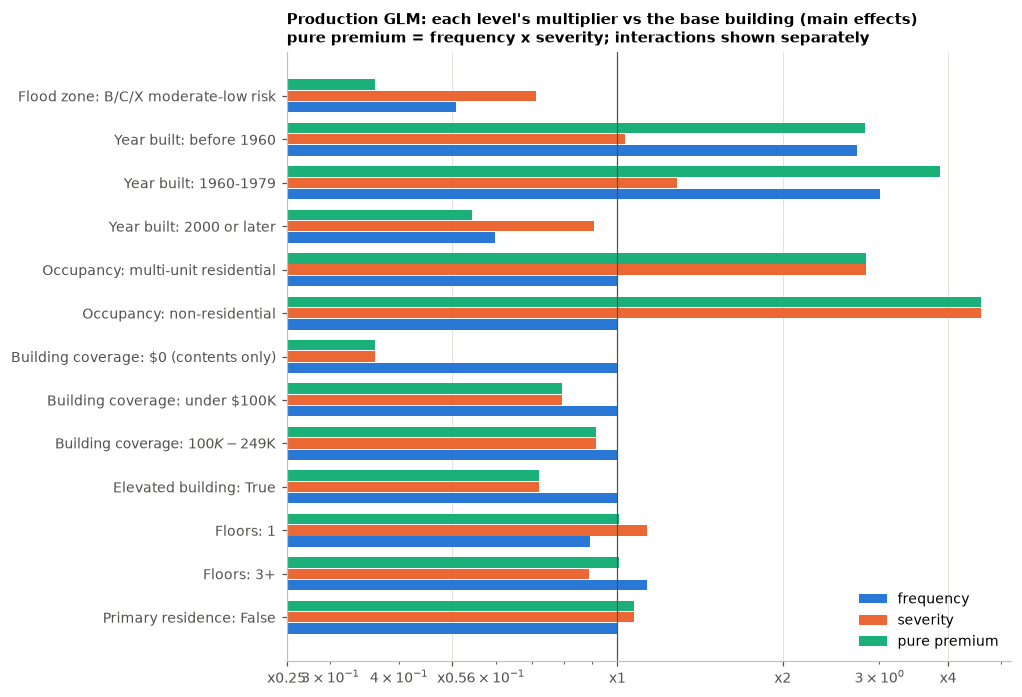

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 7.2))
R = REL[~REL["base"]].iloc[::-1].reset_index(drop=True)
y = np.arange(len(R))
for k, (col, c) in enumerate((("frequency", BLUE), ("severity", ORANGE), ("pure_premium", AQUA))):
    ax.barh(y + (k - 1) * 0.26, R[col], height=0.24, color=c, label=col.replace("_", " "), left=0)
ax.set_xscale("log"); ax.axvline(1, color=INK2, lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([f"{a}: {b}" for a, b in zip(R["feature"], R["level"])])
ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["x0.25", "x0.5", "x1", "x2", "x4"])
ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Production GLM: each level's multiplier vs the base building (main effects)\n"
             "pure premium = frequency x severity; interactions shown separately", fontsize=10)
fig.savefig(FIG / "10_glm_relativities.png"); plt.show()

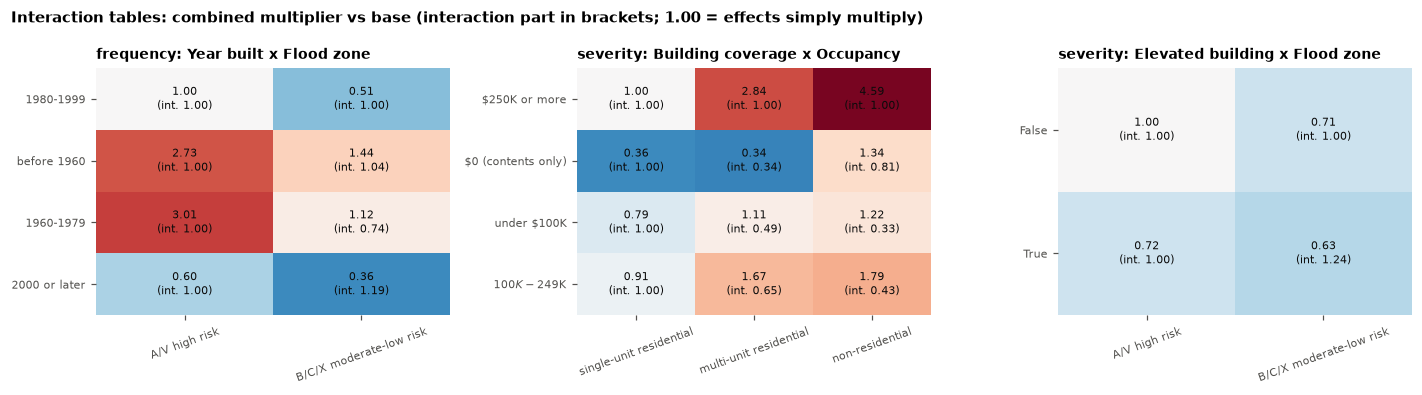

In [5]:
# The three interactions, shown as the COMBINED multiplier for each pair of levels (main effects x interaction)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
INTER_ROWS = []
for ax, (part, a, b, tab) in zip(axes, T.pairs):
    mf = T.main_f if part == "frequency" else T.main_s
    M = np.exp(mf[a][:, None] + mf[b][None, :] + tab)
    ax.imshow(np.log(M), cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}\n(int. {math.exp(tab[i, j]):.2f})", ha="center", va="center", fontsize=7.5, color=INK)
            INTER_ROWS.append({"part": part, "a": a, "level_a": T.levels[a][i], "b": b, "level_b": T.levels[b][j],
                               "combined_multiplier": M[i, j], "interaction_multiplier": math.exp(tab[i, j])})
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(T.levels[b], rotation=20, fontsize=7.5)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(T.levels[a], fontsize=7.5)
    ax.set_title(f"{part}: {NAMES[a]} x {NAMES[b]}", fontsize=9)
    ax.spines[:].set_visible(False)
fig.suptitle("Interaction tables: combined multiplier vs base (interaction part in brackets; 1.00 = effects simply multiply)",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "10_glm_interactions.png"); plt.show()
pd.DataFrame(INTER_ROWS).to_csv(REP / "09_glm_interaction_tables.csv", index=False)

### Importance across the portfolio
A relativity table says how big each multiplier is, but not how much each factor matters **across Virginia's insured buildings**. A big multiplier on a rare level matters less than a moderate one on half the portfolio.

**Measure:** the exposure-weighted average distance, on the log scale, between each building's factor contribution and the portfolio average for that factor. For a GLM this is exactly its **mean |SHAP value|** (explained in section 1b). exp(mean |SHAP|) is the **typical multiplier**: how far that factor typically moves a prediction from the average, either up or down.


**Reading the table (pure premium):**
- **Year built** (typical multiplier ×1.95, 38% of the total) and **flood zone** (×1.63, 28%) dominate. They drive both how often claims happen and how big they are, so their effects compound.
- **Occupancy** (×1.20) and the **county factor** (×1.19) come next.
- **Elevation and coverage** (×1.12 each) are moderate.
- **Primary residence** (×1.03) and **floors** (×1.00) barely move predictions. Floors' frequency and severity effects cancel (0.89 × 1.13 ≈ 1.00).
- **Occupancy has the second-largest multiplier range** (non-residential 4.6×) but ranks third: 89% of insured buildings are single-unit homes, so it moves few predictions.

In [6]:
# GLM SHAP (exact, log scale) on the Virginia portfolio (exposure-weighted) and on the claims (severity)
GLM_P = G.glm_shap(T, P, W)                                   # frequency, severity, pure_premium (+ county)
GLM_C = G.glm_shap(T, CL, None, parts=("severity",))["severity"]
GLM_C["county"] = T.county_log_factor(T.county_codes(CL["county"])) - T.county_log_factor(T.county_codes(CL["county"])).mean()
imp_glm = {"frequency": G.importance(GLM_P["frequency"], W), "severity (per claim)": G.importance(GLM_C),
           "pure premium": G.importance(GLM_P["pure_premium"], W)}
def spread(phi, w):        # exposure-weighted standard deviation of each factor's SHAP value
    return {c: math.sqrt(((phi[c] - (phi[c] * w).sum() / w.sum()) ** 2 * w).sum() / w.sum()) for c in phi}
GI = imp_glm["pure premium"].copy()
GI["sd_log"] = pd.Series(spread(GLM_P["pure_premium"], W))
rng_ = {NAMES[f]: REL[REL.feature == NAMES[f]]["pure_premium"].max() / REL[REL.feature == NAMES[f]]["pure_premium"].min() for f in E.FEATURES}
GI.index = [NAMES[i] for i in GI.index]
GI["relativity_range_max_over_min"] = pd.Series(rng_)
GI.to_csv(REP / "09_glm_importance.csv")
GI.round(3)

,mean_abs_shap,typical_multiplier,share_pct,sd_log,relativity_range_max_over_min
Year built,0.670,1.954,37.942,0.697,7.111
Flood zone,0.488,1.630,27.664,0.491,2.766
Occupancy,0.185,1.204,10.493,0.311,4.591
County factor,0.169,1.185,9.597,0.196,NaN
Elevated building,0.111,1.118,6.304,0.116,1.390
Building coverage,0.111,1.117,6.269,0.179,2.763
Primary residence,0.027,1.028,1.543,0.030,1.070
Floors,0.003,1.003,0.188,0.003,1.007


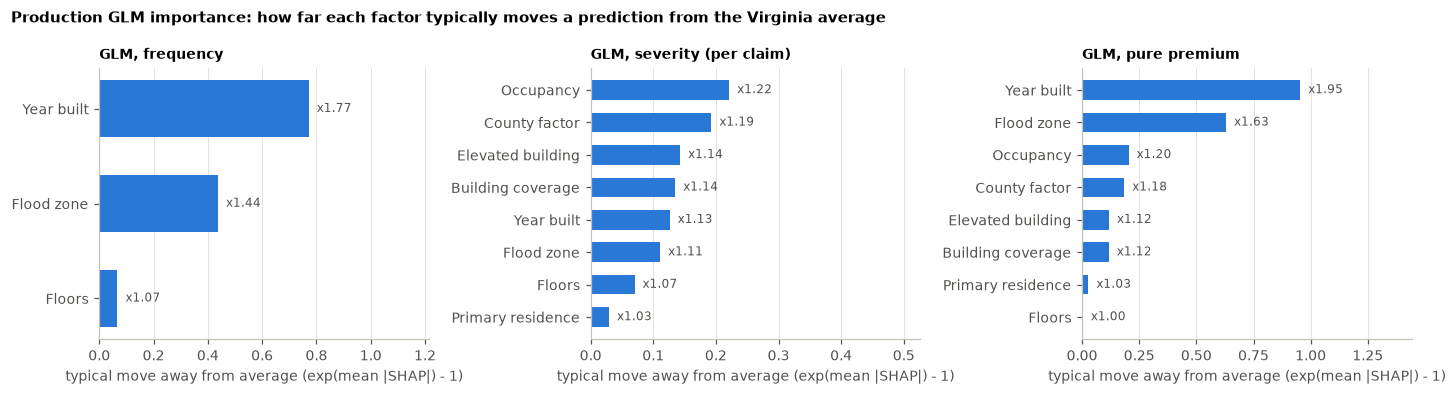

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=False)
for ax, (part, d) in zip(axes, imp_glm.items()):
    d = d[d["mean_abs_shap"] > 1e-9].iloc[::-1]
    ax.barh([NAMES[i] for i in d.index], d["typical_multiplier"] - 1, color=BLUE, height=0.6)
    for yy, v in enumerate(d["typical_multiplier"]):
        ax.text(v - 1, yy, f"  x{v:.2f}", va="center", fontsize=8, color=INK2)
    ax.set_title(f"GLM, {part}", fontsize=9); ax.set_xlabel("typical move away from average (exp(mean |SHAP|) - 1)")
    ax.set_xlim(0, d["typical_multiplier"].max() * 1.25 - 1); ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
fig.suptitle("Production GLM importance: how far each factor typically moves a prediction from the Virginia average",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "10_glm_importance.png"); plt.show()

## 1b. XGBoost: SHAP values
XGBoost has no multiplier table: a prediction is the sum of 170–940 trees. **SHAP** splits each prediction (on the log scale) into one contribution per feature. The split is the **Shapley value** from game theory: each feature gets its average extra contribution over every order in which the features could be "added".

For trees there's an exact, fast algorithm, **TreeSHAP**, built into XGBoost. Values are on the trees' log scale, so exp(SHAP) is a multiplier. Rows sum exactly to the prediction (asserted). Pure premium for XGBoost freq × sev = frequency SHAP + severity SHAP, because logs add.

In [8]:
# XGBoost SHAP values (exact TreeSHAP, log scale), additivity checked inside G.xgb_shap
XS = {}
XS["frequency"], _ = G.xgb_shap(XGB["frequency"], P)
XS["severity_cells"], _ = G.xgb_shap(XGB["severity"], P)
XS["severity"], _ = G.xgb_shap(XGB["severity"], CL)
XS["tweedie"], _ = G.xgb_shap(XGB["tweedie"], P)
XS["pure_premium"] = XS["frequency"].reindex(columns=XS["severity_cells"].columns, fill_value=0.0) + XS["severity_cells"]
print("SHAP additivity holds for all three models (asserted).")
imp_xgb = {"frequency": G.importance(XS["frequency"], W), "severity (per claim)": G.importance(XS["severity"]),
           "pure premium": G.importance(XS["pure_premium"], W), "Tweedie": G.importance(XS["tweedie"], W)}
for k, d in imp_xgb.items():
    print(f"\nXGBoost {k}:"); print(d.round(3).to_string())

SHAP additivity holds for all three models (asserted).

XGBoost frequency:
                        mean_abs_shap  typical_multiplier  share_pct
construction_band               0.408               1.504     42.600
flood_zone_group                0.289               1.335     30.155
post_firm                       0.079               1.082      8.214
building_coverage_band          0.062               1.064      6.436
floors_group                    0.043               1.044      4.533
primary_residence               0.037               1.038      3.849
occupancy_group                 0.027               1.027      2.813
elevated                        0.013               1.014      1.401

XGBoost severity (per claim):
                        mean_abs_shap  typical_multiplier  share_pct
occupancy_group                 0.225               1.252     22.866
county_group                    0.154               1.166     15.655
building_coverage_band          0.141               1.151     14.3

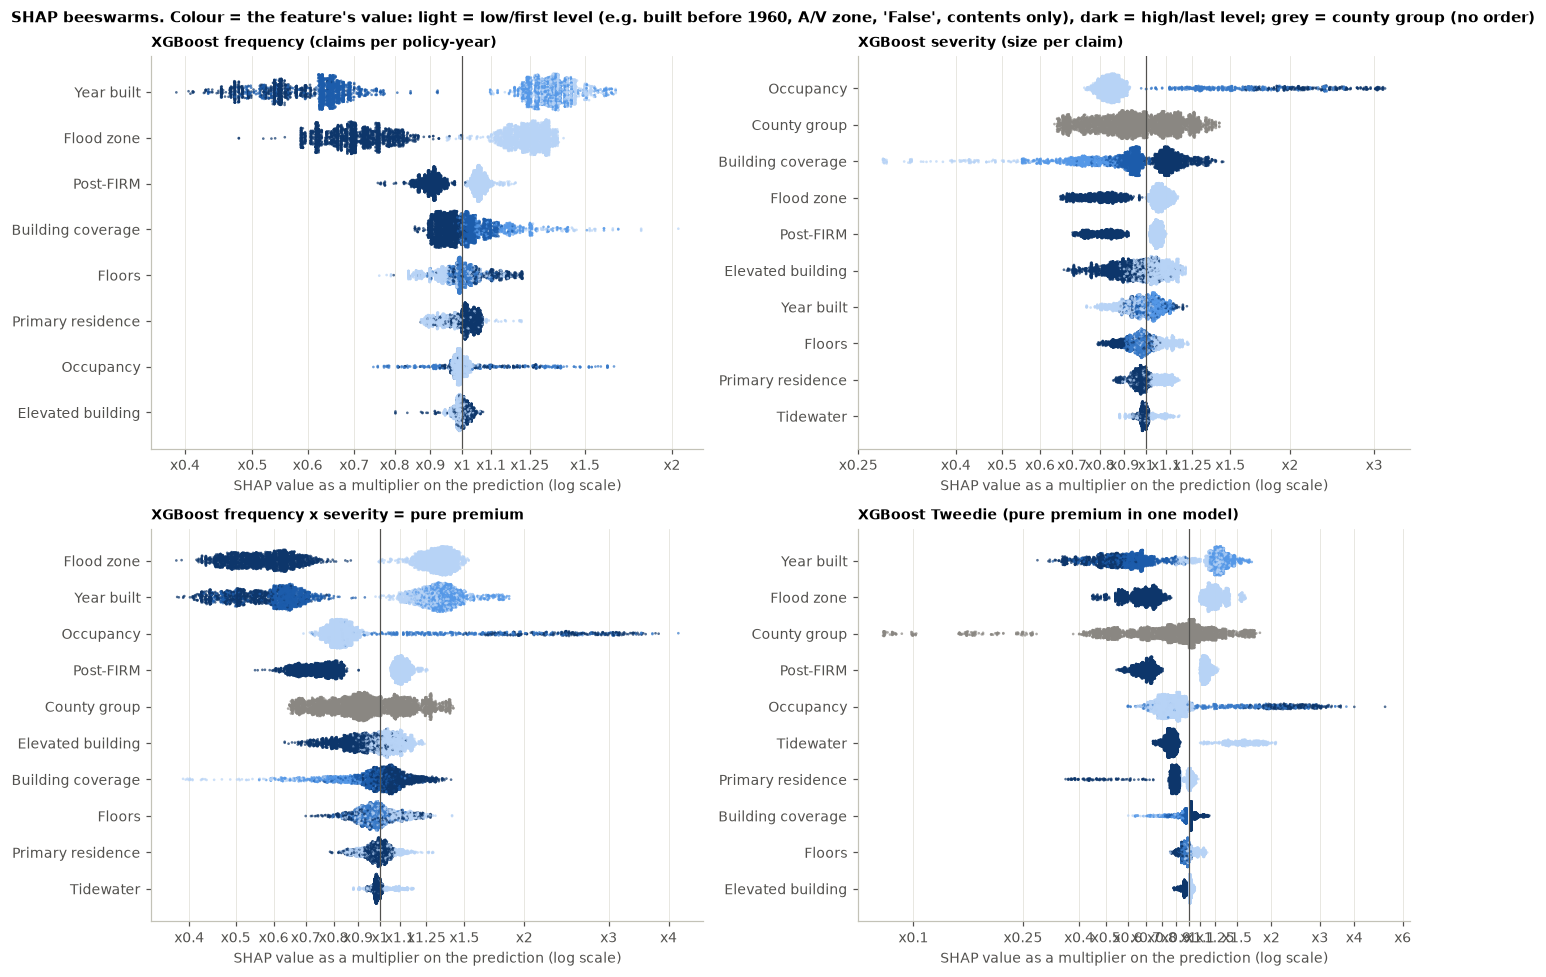

In [9]:
# Beeswarm (SHAP summary) plots. One dot = one building type x county (sampled in proportion to
# exposure, 5,000 dots) or one claim (severity). x = SHAP as a multiplier vs the model's average.
rng = np.random.default_rng(2026)
SAMPLE = rng.choice(len(P), 5000, replace=True, p=W / W.sum())
SAMPLE_C = rng.choice(len(CL), 5000, replace=False)
ORDER_LEVELS = {**X.ORDINAL, "occupancy_group": ["single-unit residential", "multi-unit residential", "non-residential"],
                "flood_zone_group": ["A/V high risk", "B/C/X moderate-low risk"]}
for f in ("elevated", "post_firm", "primary_residence", "coastal_tidal"):
    ORDER_LEVELS[f] = ["False", "True"]
from matplotlib.colors import LinearSegmentedColormap
RAMP = LinearSegmentedColormap.from_list("blue", ["#b7d3f6", "#5598e7", "#1c5cab", "#0d366b"])

def value_code(df, f):
    if f not in ORDER_LEVELS:
        return np.full(len(df), np.nan)
    lv = ORDER_LEVELS[f]
    return df[f].astype(str).map({l: i / max(len(lv) - 1, 1) for i, l in enumerate(lv)}).to_numpy(float)

def beeswarm(ax, phi, df, title, top=None):
    order = list(G.importance(phi).index)[: top or phi.shape[1]]
    for i, f in enumerate(order):
        y0 = len(order) - 1 - i
        v = phi[f].to_numpy()
        bins = np.linspace(v.min() - 1e-9, v.max() + 1e-9, 70)
        h, _ = np.histogram(v, bins)
        dens = h[np.clip(np.digitize(v, bins) - 1, 0, len(h) - 1)] / h.max()
        jit = rng.uniform(-1, 1, len(v)) * 0.4 * np.sqrt(dens)
        c = value_code(df, f)
        col = np.where(np.isnan(c)[:, None], np.array([[0.54, 0.53, 0.51, 1]]), RAMP(np.nan_to_num(c)))
        ax.scatter(np.exp(v), y0 + jit, s=3, c=col, linewidths=0, alpha=0.7, rasterized=True)
    ax.set_xscale("log"); ax.axvline(1, color=INK2, lw=0.8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([NAMES[f] for f in order][::-1])
    mult_axis(ax, "x")
    ax.set_xlabel("SHAP value as a multiplier on the prediction (log scale)")
    ax.set_title(title, fontsize=9); ax.grid(axis="x", color=GRID, lw=0.5); ax.set_axisbelow(True)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
beeswarm(axes[0, 0], XS["frequency"].iloc[SAMPLE], P.iloc[SAMPLE], "XGBoost frequency (claims per policy-year)")
beeswarm(axes[0, 1], XS["severity"].iloc[SAMPLE_C], CL.iloc[SAMPLE_C], "XGBoost severity (size per claim)")
beeswarm(axes[1, 0], XS["pure_premium"].iloc[SAMPLE], P.iloc[SAMPLE], "XGBoost frequency x severity = pure premium")
beeswarm(axes[1, 1], XS["tweedie"].iloc[SAMPLE], P.iloc[SAMPLE], "XGBoost Tweedie (pure premium in one model)")
fig.suptitle("SHAP beeswarms. Colour = the feature's value: light = low/first level (e.g. built before 1960, A/V zone, "
             "'False', contents only), dark = high/last level; grey = county group (no order)",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "10_shap_beeswarm.png"); plt.show()

In [10]:
# SHAP interaction values on a 3,000-row sample (the lighter approach; exact on the sample)
INTER = {}
for k, df, idx in (("frequency", P, SAMPLE[:3000]), ("severity", CL, SAMPLE_C[:3000]), ("tweedie", P, SAMPLE[:3000])):
    Mx, raw = G.xgb_interactions(XGB[k], df.iloc[idx])
    INTER[k] = (Mx, raw, df.iloc[idx], idx)
rows = []
for k, (Mx, *_r) in INTER.items():
    feats = list(Mx.index)
    for i, a in enumerate(feats):
        for b in feats[i + 1:]:
            rows.append({"model": k, "a": a, "b": b, "mean_abs_interaction": Mx.loc[a, b]})
IT = pd.DataFrame(rows).sort_values(["model", "mean_abs_interaction"], ascending=[True, False])
IT.to_csv(REP / "09_xgb_shap_interactions.csv", index=False)
IT.groupby("model").head(4).round(4)

,model,a,b,mean_abs_interaction
0,frequency,flood_zone_group,construction_band,0.0739
12,frequency,construction_band,floors_group,0.0607
1,frequency,flood_zone_group,building_coverage_band,0.0539
5,frequency,flood_zone_group,primary_residence,0.0418
45,severity,building_coverage_band,occupancy_group,0.0713
62,severity,elevated,county_group,0.0650
60,severity,elevated,floors_group,0.0558
57,severity,occupancy_group,county_group,0.0475
99,tweedie,occupancy_group,primary_residence,0.1752
102,tweedie,occupancy_group,county_group,0.0995


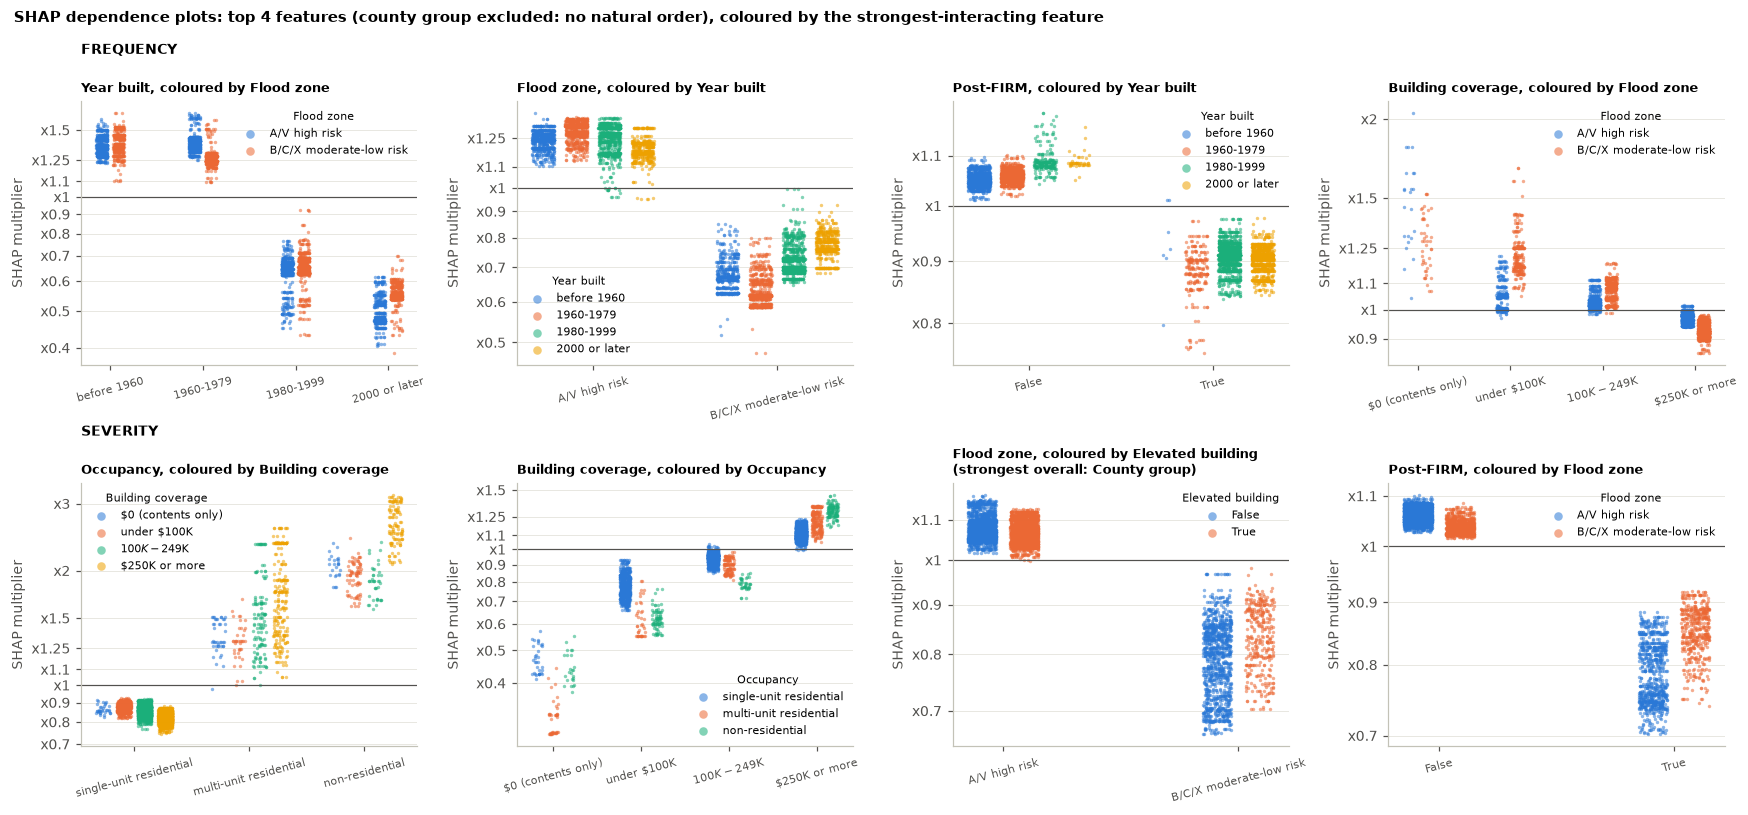

Top features: {'frequency': ['construction_band', 'flood_zone_group', 'post_firm', 'building_coverage_band'], 'severity': ['occupancy_group', 'building_coverage_band', 'flood_zone_group', 'post_firm']}


In [11]:
def strongest_partner(k, f, max_levels=4):
    Mx = INTER[k][0]
    cand = Mx.loc[f].drop(f)
    cand = cand[[c for c in cand.index if c in ORDER_LEVELS and len(ORDER_LEVELS[c]) <= max_levels]]
    return cand.idxmax(), Mx.loc[f].drop(f).idxmax()

def dependence(axes, k, phi, df, feats):
    for ax, f in zip(axes, feats):
        partner, overall = strongest_partner(k, f)
        lv = ORDER_LEVELS[f]
        xpos = df[f].astype(str).map({l: i for i, l in enumerate(lv)}).to_numpy(float)
        pl = ORDER_LEVELS[partner]
        pc = df[partner].astype(str).map({l: i for i, l in enumerate(pl)}).to_numpy(int)
        for j, l in enumerate(pl):
            s = pc == j
            ax.scatter(xpos[s] + (j - (len(pl) - 1) / 2) * 0.18 + rng.uniform(-0.06, 0.06, s.sum()),
                       np.exp(phi[f].to_numpy()[s]), s=5, color=CAT[j], alpha=0.55, linewidths=0, label=l, rasterized=True)
        ax.set_yscale("log"); ax.axhline(1, color=INK2, lw=0.8)
        mult_axis(ax, "y")
        ax.set_xticks(range(len(lv))); ax.set_xticklabels(lv, rotation=15, fontsize=7.5)
        ax.set_ylabel("SHAP multiplier"); ax.grid(axis="y", color=GRID, lw=0.5); ax.set_axisbelow(True)
        note = "" if partner == overall else f"\n(strongest overall: {NAMES[overall]})"
        ax.set_title(f"{NAMES[f]}, coloured by {NAMES[partner]}{note}", fontsize=8.5)
        ax.legend(frameon=False, fontsize=7, markerscale=2.5, title=NAMES[partner], title_fontsize=7)

TOP = {k: [f for f in G.importance(XS[k if k != 'severity' else 'severity'], W if k != 'severity' else None).index
           if f in ORDER_LEVELS][:4] for k in ("frequency", "severity")}
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
dependence(axes[0], "frequency", XS["frequency"].iloc[SAMPLE], P.iloc[SAMPLE], TOP["frequency"])
dependence(axes[1], "severity", XS["severity"].iloc[SAMPLE_C], CL.iloc[SAMPLE_C], TOP["severity"])
axes[0, 0].annotate("FREQUENCY", (0, 1.18), xycoords="axes fraction", fontweight="bold")
axes[1, 0].annotate("SEVERITY", (0, 1.18), xycoords="axes fraction", fontweight="bold")
fig.suptitle("SHAP dependence plots: top 4 features (county group excluded: no natural order), coloured by the strongest-interacting feature",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "10_shap_dependence.png"); plt.show()
print("Top features:", TOP)

In [12]:
# The strongest interaction in each model, as a table of the average interaction multiplier by level pair
def interaction_table(k, a, b):
    Mx, raw, df, idx = INTER[k]
    iv = G.interaction_values_by_feature(XGB[k], raw, a, b)
    t = pd.DataFrame({a: df[a].astype(str).to_numpy(), b: df[b].astype(str).to_numpy(), "iv": iv})
    return np.exp(t.groupby([a, b])["iv"].mean()).unstack().reindex(index=ORDER_LEVELS.get(a), columns=ORDER_LEVELS.get(b))
for k, a, b in (("frequency", "construction_band", "flood_zone_group"), ("severity", "building_coverage_band", "occupancy_group")):
    print(f"\nXGBoost {k}: average SHAP interaction multiplier, {NAMES[a]} x {NAMES[b]}")
    print(interaction_table(k, a, b).round(2).to_string())


XGBoost frequency: average SHAP interaction multiplier, Year built x Flood zone
flood_zone_group   A/V high risk  B/C/X moderate-low risk
construction_band                                        
before 1960                 0.99                     0.99
1960-1979                   1.05                     0.87
1980-1999                   1.01                     1.08
2000 or later               0.92                     1.21

XGBoost severity: average SHAP interaction multiplier, Building coverage x Occupancy
occupancy_group         single-unit residential  multi-unit residential  non-residential
building_coverage_band                                                                  
$0 (contents only)                         1.12                    0.56             0.84
under $100K                                1.10                    0.72             0.70
$100K-$249K                                1.04                    0.93             0.73
$250K or more                           

### SHAP importance vs GLM importance, like for like
Both models are measured with the same yardstick: mean |SHAP|, on the same rows, on the log scale.
- **GLM SHAP is exact and closed-form.** A main effect contributes term − average term. An interaction is shared between its two features by the two-player Shapley formula.
- **Geography:** the GLM's county factor is compared with XGBoost's county group + Tidewater.
- **Post-FIRM:** it's in XGBoost but not in the GLM.
- *Small technical difference, disclosed:* XGBoost's TreeSHAP uses the trees' own training distribution as the "average", while the GLM uses the exposure-weighted portfolio.

In [13]:
PLAYERS = E.FEATURES + ["post_firm", "geography"]
def to_players(phi):
    out = pd.DataFrame(index=phi.index)
    for p in PLAYERS:
        if p == "geography":
            cols = [c for c in ("county", "county_group", "coastal_tidal") if c in phi]
            out[p] = phi[cols].sum(axis=1) if cols else 0.0
        else:
            out[p] = phi[p] if p in phi else 0.0
    return out
PAIRS = {"frequency": (GLM_P["frequency"], XS["frequency"], W),
         "severity (per claim)": (GLM_C, XS["severity"], None),
         "pure premium": (GLM_P["pure_premium"], XS["pure_premium"], W)}
rows = []
for part, (g, x, w) in PAIRS.items():
    ig, ix = G.importance(to_players(g), w), G.importance(to_players(x), w)
    it = G.importance(to_players(XS["tweedie"]), W) if part == "pure premium" else None
    for p in PLAYERS:
        rows.append({"part": part, "feature": NAMES[p], "GLM_mean_abs_shap": ig.loc[p, "mean_abs_shap"],
                     "XGB_mean_abs_shap": ix.loc[p, "mean_abs_shap"],
                     "GLM_rank": int(ig.index.get_loc(p)) + 1, "XGB_rank": int(ix.index.get_loc(p)) + 1,
                     "XGB_Tweedie_mean_abs_shap": it.loc[p, "mean_abs_shap"] if it is not None else np.nan})
CMP = pd.DataFrame(rows)
CMP.to_csv(REP / "09_importance_comparison.csv", index=False)
for part, d in CMP.groupby("part", sort=False):
    rho = d[["GLM_mean_abs_shap", "XGB_mean_abs_shap"]].corr(method="spearman").iloc[0, 1]
    print(f"{part}: Spearman rank correlation of importances = {rho:.2f}")
CMP.round(3)

frequency: Spearman rank correlation of importances = 0.70
severity (per claim): Spearman rank correlation of importances = 0.67
pure premium: Spearman rank correlation of importances = 0.72


,part,feature,GLM_mean_abs_shap,XGB_mean_abs_shap,GLM_rank,XGB_rank,XGB_Tweedie_mean_abs_shap
0,frequency,Flood zone,0.363,0.289,2,2,NaN
1,frequency,Year built,0.572,0.408,1,1,NaN
2,frequency,Occupancy,0.000,0.027,5,7,NaN
3,frequency,Building coverage,0.000,0.062,4,4,NaN
4,frequency,Elevated building,0.000,0.013,6,8,NaN
5,frequency,Floors,0.065,0.043,3,5,NaN
6,frequency,Primary residence,0.000,0.037,7,6,NaN
7,frequency,Post-FIRM,0.000,0.079,8,3,NaN
8,frequency,Geography (county),0.000,0.000,9,9,NaN
9,severity (per claim),Flood zone,0.105,0.114,6,4,NaN


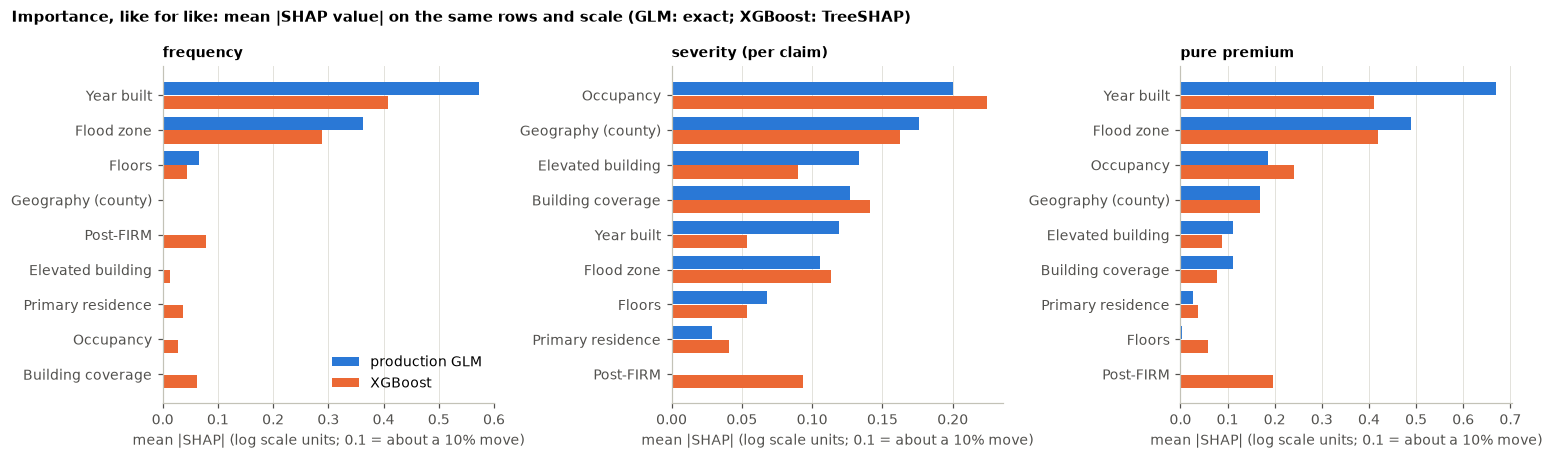

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (part, d) in zip(axes, CMP.groupby("part", sort=False)):
    d = d.sort_values("GLM_mean_abs_shap").reset_index(drop=True)
    yy = np.arange(len(d))
    ax.barh(yy + 0.2, d["GLM_mean_abs_shap"], height=0.38, color=BLUE, label="production GLM")
    ax.barh(yy - 0.2, d["XGB_mean_abs_shap"], height=0.38, color=ORANGE, label="XGBoost")
    ax.set_yticks(yy); ax.set_yticklabels(d["feature"]); ax.set_title(part, fontsize=9)
    ax.set_xlabel("mean |SHAP| (log scale units; 0.1 = about a 10% move)")
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("Importance, like for like: mean |SHAP value| on the same rows and scale (GLM: exact; XGBoost: TreeSHAP)",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "10_importance_shap_vs_glm.png"); plt.show()

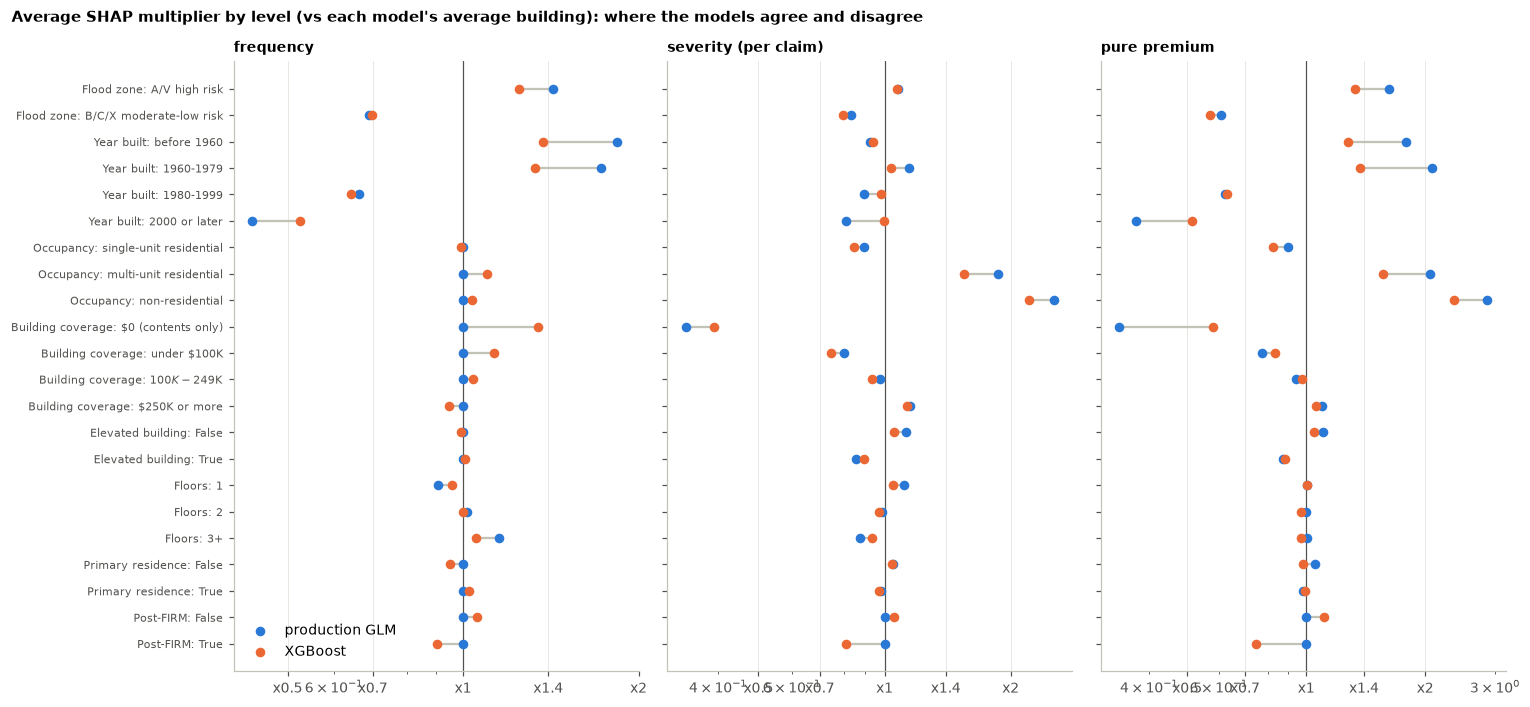

,part,feature,level,GLM,XGB,same_direction
6,frequency,Occupancy,single-unit residential,1.000,0.992,False
7,frequency,Occupancy,multi-unit residential,1.000,1.098,False
8,frequency,Occupancy,non-residential,1.000,1.038,False
9,frequency,Building coverage,$0 (contents only),1.000,1.346,False
10,frequency,Building coverage,under $100K,1.000,1.130,False
11,frequency,Building coverage,$100K-$249K,1.000,1.041,False
12,frequency,Building coverage,$250K or more,1.000,0.945,False
13,frequency,Elevated building,False,1.000,0.992,False
14,frequency,Elevated building,True,1.000,1.008,False
18,frequency,Primary residence,False,1.000,0.949,False


In [15]:
# Average SHAP multiplier for each LEVEL (vs that model's average): do the two models agree on direction and size?
rows = []
for part, (g, x, w) in PAIRS.items():
    df = CL if part.startswith("severity") else P
    for f in E.FEATURES + ["post_firm"]:
        eg = G.effect_by_level(to_players(g), df, f, w) if f in E.FEATURES else None
        ex = G.effect_by_level(to_players(x), df, f, w)
        for lvl in ORDER_LEVELS[f]:
            rows.append({"part": part, "feature": NAMES[f], "level": lvl,
                         "GLM": float(eg[lvl]) if eg is not None else 1.0, "XGB": float(ex[lvl])})
LVL = pd.DataFrame(rows)
LVL["same_direction"] = np.sign(np.log(LVL["GLM"]).round(3)) == np.sign(np.log(LVL["XGB"]).round(3))
LVL.to_csv(REP / "09_effect_by_level.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 6.5), sharey=True)
labels = None
for ax, (part, d) in zip(axes, LVL.groupby("part", sort=False)):
    d = d.reset_index(drop=True)
    yy = np.arange(len(d))[::-1]
    ax.hlines(yy, d["GLM"], d["XGB"], color="#c3c2b7", lw=1.5)
    ax.scatter(d["GLM"], yy, color=BLUE, s=28, label="production GLM", zorder=3)
    ax.scatter(d["XGB"], yy, color=ORANGE, s=28, label="XGBoost", zorder=3)
    ax.set_xscale("log"); ax.axvline(1, color=INK2, lw=0.8); ax.set_title(part, fontsize=9)
    ax.set_xticks([0.5, 0.7, 1, 1.4, 2]); ax.set_xticklabels(["x0.5", "x0.7", "x1", "x1.4", "x2"])
    ax.grid(axis="x", color=GRID, lw=0.5); ax.set_axisbelow(True)
    labels = [f"{a}: {b}" for a, b in zip(d["feature"], d["level"])]
axes[0].set_yticks(np.arange(len(labels))[::-1]); axes[0].set_yticklabels(labels, fontsize=7.5)
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Average SHAP multiplier by level (vs each model's average building): where the models agree and disagree",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "10_effect_by_level.png"); plt.show()
LVL[~LVL["same_direction"]].round(3)

In [16]:
# Elevation in XGBoost frequency, building by building: share of elevated exposure pushed UP by "elevated"
el = (P["elevated"].astype(str) == "True").to_numpy()
up = XS["frequency"]["elevated"].to_numpy() > 0
print(f"XGBoost frequency: elevated buildings whose 'elevated' SHAP raises frequency: "
      f"{100 * W[el & up].sum() / W[el].sum():.0f}% of elevated exposure")
print(f"XGBoost severity: elevated claims whose 'elevated' SHAP raises claim size: "
      f"{100 * ((CL['elevated'].astype(str) == 'True') & (XS['severity']['elevated'] > 0)).sum() / (CL['elevated'].astype(str) == 'True').sum():.0f}%")
print(f"Production GLM: elevated multiplier on frequency = 1.00 (not in the frequency model); on severity "
      f"{math.exp(T.main_s['elevated'][T.idx['elevated']['True']]):.2f} (A/V) before the zone interaction")

XGBoost frequency: elevated buildings whose 'elevated' SHAP raises frequency: 76% of elevated exposure
XGBoost severity: elevated claims whose 'elevated' SHAP raises claim size: 9%
Production GLM: elevated multiplier on frequency = 1.00 (not in the frequency model); on severity 0.72 (A/V) before the zone interaction


### Where the models agree
- **The same top three for pure premium:** year built, flood zone, occupancy. Rank correlations of the importances are 0.70 (frequency), 0.67 (severity) and 0.72 (pure premium).
- **Geography has the same weight in both** (mean |SHAP| 0.169 vs 0.169 for pure premium), and it's #2 for severity in both. Two very different methods agree: Bühlmann–Straub credibility on county A/E, and trees on county group + Tidewater.
- **The interactions XGBoost found are the ones the hybrid GLM now has:**
  - **Frequency, year built × zone:** XGBoost's 1960–79 × B/C/X interaction averages ×0.87 and 2000+ × B/C/X ×1.21. The GLM's are ×0.74 and ×1.19.
  - **Severity, coverage × occupancy:** XGBoost shrinks low-limit multi-unit and non-residential claims (×0.56–0.73) and lifts $250K+ non-residential (×1.27). The GLM's interaction cells are ×0.33–0.65.

### Where they disagree, and why
1. **Post-FIRM.** XGBoost gives it real weight (pure premium 0.197, #4); the GLM gives it none, because it failed the storm-aware keep rule. That doesn't mean the GLM ignores what post-FIRM measures. Post-FIRM and year built carry overlapping information, and **SHAP shares credit among correlated features however the model happens to split it**. XGBoost's year built + post-FIRM (0.41 + 0.20) ≈ the GLM's year built alone (0.67). Same signal, different labels.
2. **Small frequency effects XGBoost uses and the GLM rejected:**
   - contents-only cover (×1.35 frequency);
   - multi-unit (×1.10);
   - primary residence.
   These failed the GLM's unseen-year keep rule. XGBoost's +1.8 frequency points (Milestone 11) partly come from here.
3. **Elevation in frequency:** in XGBoost, "elevated" **raises** claim frequency for 76% of elevated exposure. Milestone 11 found 78% by flipping the feature. Elevation can't cause claims. The trees picked up *where* elevated buildings are (coastal V zones that storms hit). The GLM has no frequency term for elevation.
4. **Floors:** XGBoost gives floors some pure-premium weight (0.058). In the GLM its frequency and severity effects cancel (0.003).
5. **The Tweedie** puts geography first in all but name (county group + Tidewater = 0.42) and almost ignores coverage (0.04). That's the same flat-coverage weakness seen in Milestones 9–10.

**Bottom line:** both models agree on what matters most and in which direction. XGBoost's extra accuracy comes mainly from many small, interacting effects that are hard to defend one by one (post-FIRM on top of year built, coverage in frequency) and from finer geography. The hybrid GLM already captures the two biggest interactions.

## 1c. "Explains the model, not the world"
A SHAP value or relativity says how the **model's prediction** changes with a feature, holding the model's other inputs fixed. It does **not** say what would happen to a real building if you changed that feature. Features stand in (are **proxies**) for things we don't observe.

In [17]:
# Coverage band: what else changes between bands? (exposure shares, Virginia 2010-2025)
cov_lv = X.ORDINAL["building_coverage_band"]
g = P.assign(nonsingle=P["occupancy_group"].astype(str) != "single-unit residential",
             av=P["flood_zone_group"].astype(str) == "A/V high risk",
             old=P["construction_band"].astype(str).isin(["before 1960", "1960-1979"]))
rows = []
for lvl in cov_lv:
    s = g[g["building_coverage_band"].astype(str) == lvl]; w = s["exposure"]
    c = CL[CL["building_coverage_band"].astype(str) == lvl]
    rows.append({"coverage band": lvl, "% of exposure": 100 * w.sum() / W.sum(),
                 "% multi-unit or non-residential": 100 * (w * s["nonsingle"]).sum() / w.sum(),
                 "% A/V zone": 100 * (w * s["av"]).sum() / w.sum(),
                 "% built before 1980": 100 * (w * s["old"]).sum() / w.sum(),
                 "claims": len(c), "average claim (2025 $)": c[X.sv.TARGET].mean() if len(c) else np.nan,
                 "% claims at a policy limit": 100 * c["any_limit_hit"].mean() if len(c) else np.nan,
                 "GLM severity relativity (single-unit)": math.exp(T.main_s["building_coverage_band"][T.idx["building_coverage_band"][lvl]])})
PROXY = pd.DataFrame(rows)
PROXY.to_csv(REP / "09_proxy_coverage.csv", index=False)
PROXY.round(2)

,coverage band,% of exposure,% multi-unit or non-residential,% A/V zone,% built before 1980,claims,average claim (2025 $),% claims at a policy limit,GLM severity relativity (single-unit)
0,$0 (contents only),1.36,56.16,37.37,36.38,199,16076.68,10.05,0.36
1,under $100K,9.36,16.29,54.73,59.89,1291,19875.53,5.65,0.79
2,$100K-$249K,28.42,7.38,64.81,62.25,3671,28901.45,1.31,0.91
3,$250K or more,60.86,10.37,44.20,43.18,4384,35264.76,0.80,1.00


In [18]:
# Elevated: Simpson's paradox again (one-way vs model)
cl = va.assign(el=va["elevated"].astype(str), zone=va["flood_zone_group"].astype(str))
one = cl.groupby("el")[[X.LOSS, "exposure"]].sum(); one = one[X.LOSS] / one["exposure"]
byz = cl.groupby(["zone", "el"])[[X.LOSS, "exposure"]].sum(); byz = (byz[X.LOSS] / byz["exposure"]).unstack()
share = cl.groupby("el").apply(lambda d: 100 * d.loc[d.zone == "A/V high risk", "exposure"].sum() / d["exposure"].sum())
print(f"Actual loss cost, elevated vs not (one-way): x{one['True'] / one['False']:.2f}")
print("Within each zone:", (byz["True"] / byz["False"]).round(2).to_dict())
print(f"% in A/V zones: elevated {share['True']:.0f}%, not elevated {share['False']:.0f}%")
print(f"Production GLM severity multiplier for elevated: A/V x{math.exp(T.main_s['elevated'][1]):.2f}, "
      f"B/C/X x{math.exp(T.main_s['elevated'][1] + T.pairs[2][3][1, 1] if T.pairs[2][1] == 'elevated' else float('nan')):.2f}")

Actual loss cost, elevated vs not (one-way): x0.58
Within each zone: {'A/V high risk': 0.4, 'B/C/X moderate-low risk': 0.57}
% in A/V zones: elevated 67%, not elevated 40%
Production GLM severity multiplier for elevated: A/V x0.72, B/C/X x0.89


**Coverage band is a proxy for building value and type.**
- The GLM's severity multiplier for single-unit homes with under $100K of building cover is ×0.79, and ×0.36 for contents-only.
- Read causally, that would say "buy less cover and your flood damage shrinks." That's wrong. Water does the same damage whatever you bought.
- What coverage really measures is **what's insured:** smaller or cheaper buildings buy lower limits. 56% of contents-only exposure is multi-unit or non-residential (units in a building insured elsewhere), vs 10% for $250K+ cover.
- Only one part is genuinely causal: **the limit caps the payout.** 5.7% of under-$100K claims hit a policy limit, vs 0.8% for $250K+. A low limit makes the insurer's loss smaller even when the damage isn't.

**Elevated: Simpson's paradox.**
- Elevated buildings sit mostly in high-risk zones (67% in A/V vs 40% of non-elevated).
- So the one-way gap in actual loss cost (×0.58) *understates* the benefit within each zone (×0.40 in A/V, ×0.57 in B/C/X).
- The GLM credits elevation with ×0.72 on claim size (A/V). Part of the within-zone gap is credited to the year-built factor instead, because elevated buildings are also newer.
- XGBoost's frequency model goes the other way (it raises frequency for 76% of elevated exposure). It learned *where* elevated buildings are, not what elevation does.

**Year built is a proxy too.**
- The ×3.86 pure-premium multiplier for 1960–79 isn't about age itself.
- These buildings were mostly built **before flood maps and elevation rules** (pre-FIRM), often in older, low-lying neighbourhoods.
- Renovating a 1970s house doesn't make it a 2000s house in the model's sense; raising it above flood level would. The model doesn't observe that directly.

**What this means for the app:** explanations say what *the model* associates with higher expected losses for *groups* of insured buildings. They don't say why a particular building floods, or what an owner should change. The app's wording ("mainly because 61% of insured buildings are in A/V zones") stays descriptive and area-level.

## 2. Local explanations: waterfalls for example profiles and counties
`explain.explain_profile` starts at the **Virginia average** expected loss per policy-year. It then shows how each factor of the profile, plus its county factor, moves the number.

The steps are **multiplicative Shapley values**:
- "Setting" a factor means giving every insured building in Virginia the profile's level and re-averaging.
- Each factor's step is averaged over all 2⁸ = 256 orders of setting the factors, so it doesn't depend on any chosen order.
- The steps multiply exactly to the profile's expected loss.
- It's SHAP for the GLM, with Virginia's insured portfolio as the background.

The exact **rating worksheet** (base building × multipliers) is also returned (`result["worksheet"]`).

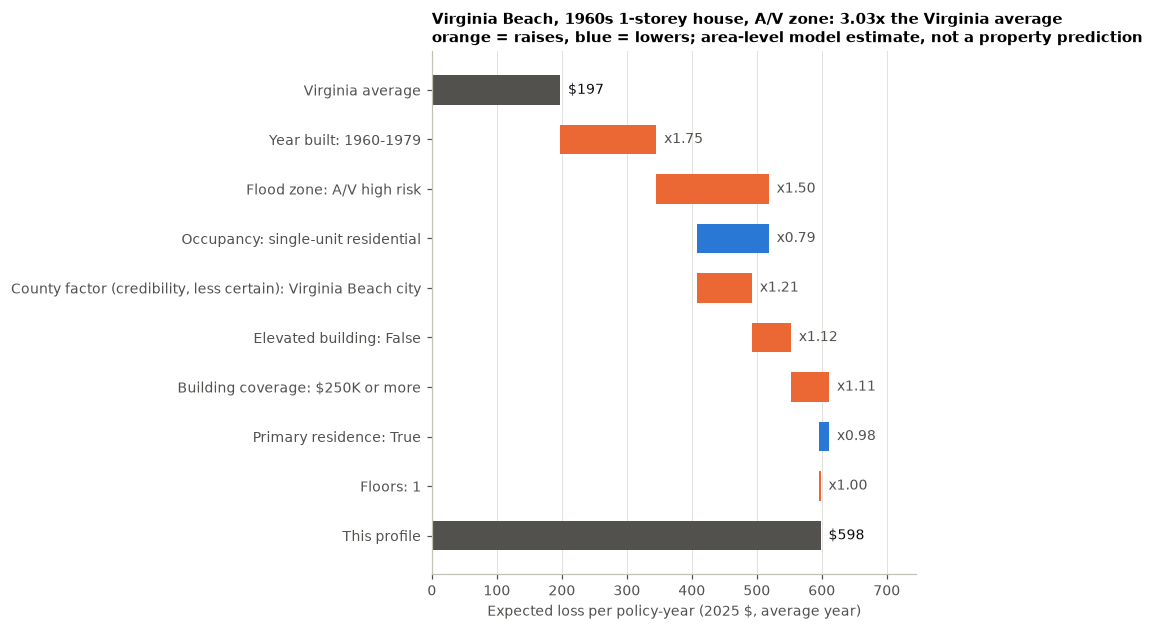

For insured buildings with this profile in Virginia Beach city, the model's expected flood loss is about $598 per policy-year in an average year, about 3.0x the Virginia average, mainly because it was built in 1960-1979 and it is in a high-risk A/V flood zone. This describes the average for a group of similar insured buildings, not a quote or a prediction for any individual property. 



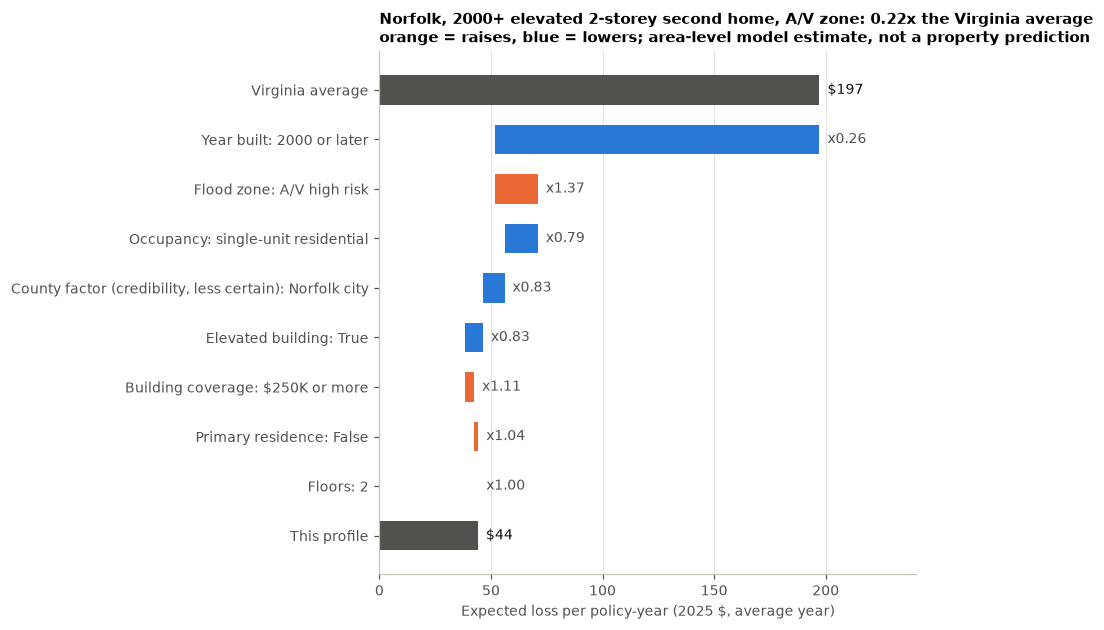

For insured buildings with this profile in Norfolk city, the model's expected flood loss is about $44 per policy-year in an average year, about 78% below the Virginia average, mainly because it was built in 2000 or later and it is a single-unit home (claims are smaller than for apartment and commercial buildings). This describes the average for a group of similar insured buildings, not a quote or a prediction for any individual property. 



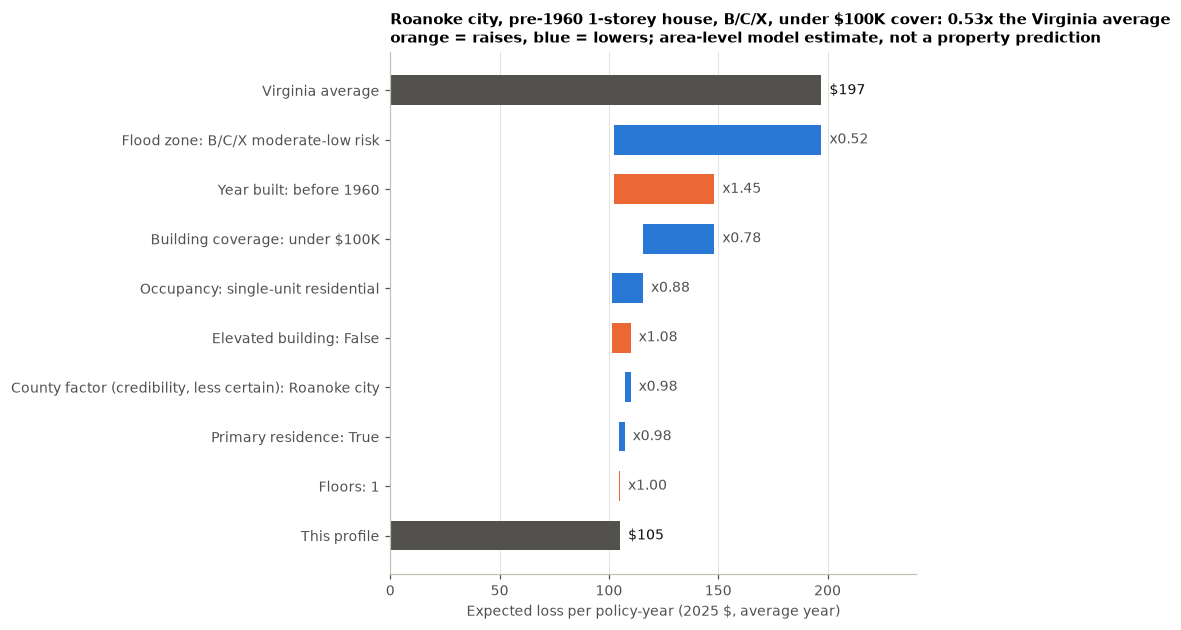

For insured buildings with this profile in Roanoke city, the model's expected flood loss is about $105 per policy-year in an average year, about 47% below the Virginia average, mainly because it is in a moderate/low-risk B/C/X zone and it has building cover under $100K. This describes the average for a group of similar insured buildings, not a quote or a prediction for any individual property. 



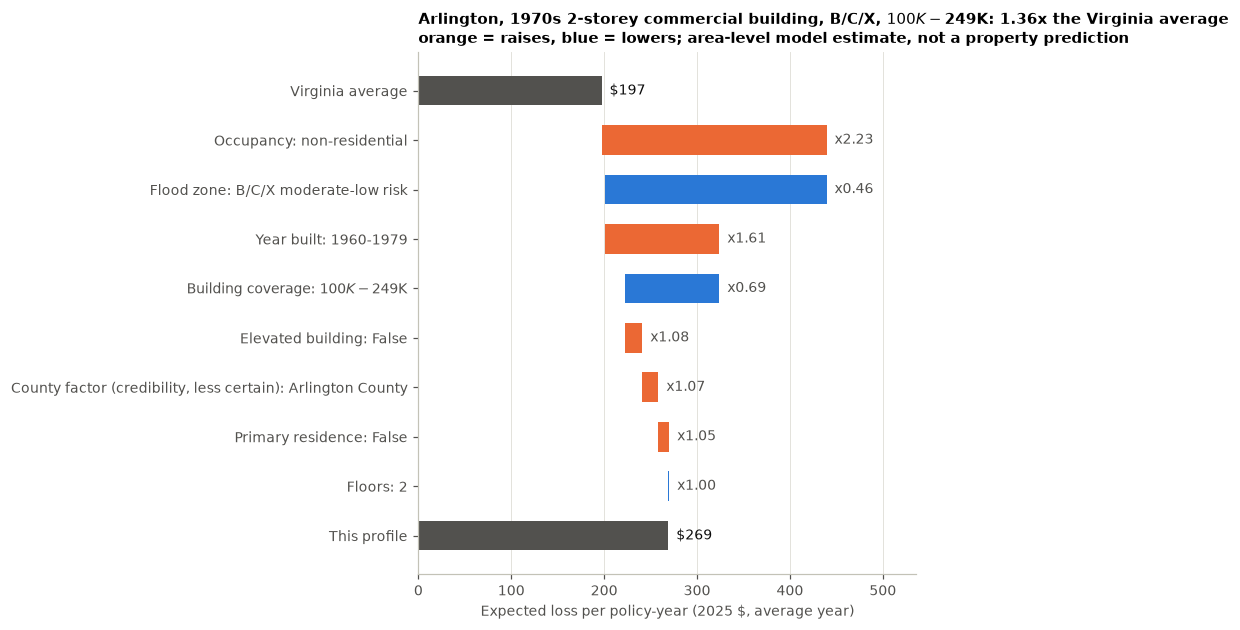

For insured buildings with this profile in Arlington County, the model's expected flood loss is about $269 per policy-year in an average year, about 1.4x the Virginia average, mainly because it is a non-residential building and it was built in 1960-1979. This describes the average for a group of similar insured buildings, not a quote or a prediction for any individual property. 



,profile,frequency_per_1000,severity,county_factor,pure_premium,ratio_to_virginia,certainty
0,"Virginia Beach, 1960s 1-storey house, A/V zone",12.429,39904.087,1.213,598.070,3.033,High
1,"Norfolk, 2000+ elevated 2-storey second home, A/V zone",2.782,19159.858,0.833,44.138,0.224,High
2,"Roanoke city, pre-1960 1-storey house, B/C/X, under $100K cover",5.957,18111.794,0.980,105.094,0.533,Medium
3,"Arlington, 1970s 2-storey commercial building, B/C/X, $100K-$249K",5.223,48148.117,1.076,269.008,1.364,Medium


In [19]:
PROFILES = {
    "virginia_beach_1960s_house": ("Virginia Beach, 1960s 1-storey house, A/V zone",
        {"county": "51810", "flood_zone_group": "A/V high risk", "construction_band": "1960-1979", "floors_group": "1",
         "occupancy_group": "single-unit residential", "building_coverage_band": "$250K or more", "elevated": "False", "primary_residence": "True"}),
    "norfolk_elevated_second_home": ("Norfolk, 2000+ elevated 2-storey second home, A/V zone",
        {"county": "51710", "flood_zone_group": "A/V high risk", "construction_band": "2000 or later", "floors_group": "2",
         "occupancy_group": "single-unit residential", "building_coverage_band": "$250K or more", "elevated": "True", "primary_residence": "False"}),
    "roanoke_pre1960_low_cover": ("Roanoke city, pre-1960 1-storey house, B/C/X, under $100K cover",
        {"county": "51770", "flood_zone_group": "B/C/X moderate-low risk", "construction_band": "before 1960", "floors_group": "1",
         "occupancy_group": "single-unit residential", "building_coverage_band": "under $100K", "elevated": "False", "primary_residence": "True"}),
    "arlington_1970s_commercial": ("Arlington, 1970s 2-storey commercial building, B/C/X, $100K-$249K",
        {"county": "51013", "flood_zone_group": "B/C/X moderate-low risk", "construction_band": "1960-1979", "floors_group": "2",
         "occupancy_group": "non-residential", "building_coverage_band": "$100K-$249K", "elevated": "False", "primary_residence": "False"}),
}
PROF_ROWS = []
for slug, (title, prof) in PROFILES.items():
    r = EX.explain_profile(prof)
    E.plot_waterfall(r, FIG / f"10_waterfall_profile_{slug}.png", title=title); plt.show()
    print(r["sentence"], "\n")
    wf = r["waterfall"]
    PROF_ROWS.append({"profile": title, "frequency_per_1000": 1000 * r["frequency"], "severity": r["severity"],
                      "county_factor": r["county_factor"], "pure_premium": r["pure_premium"],
                      "ratio_to_virginia": r["ratio_to_virginia"], "certainty": r["certainty"],
                      "steps": "; ".join(f"{s} x{m:.2f}" for s, m in zip(wf["step"][1:-1], wf["multiplier"][1:-1])),
                      "sentence": r["sentence"]})
PROF = pd.DataFrame(PROF_ROWS); PROF.to_csv(REP / "09_example_profiles.csv", index=False)
PROF.drop(columns=["steps", "sentence"]).round(3)

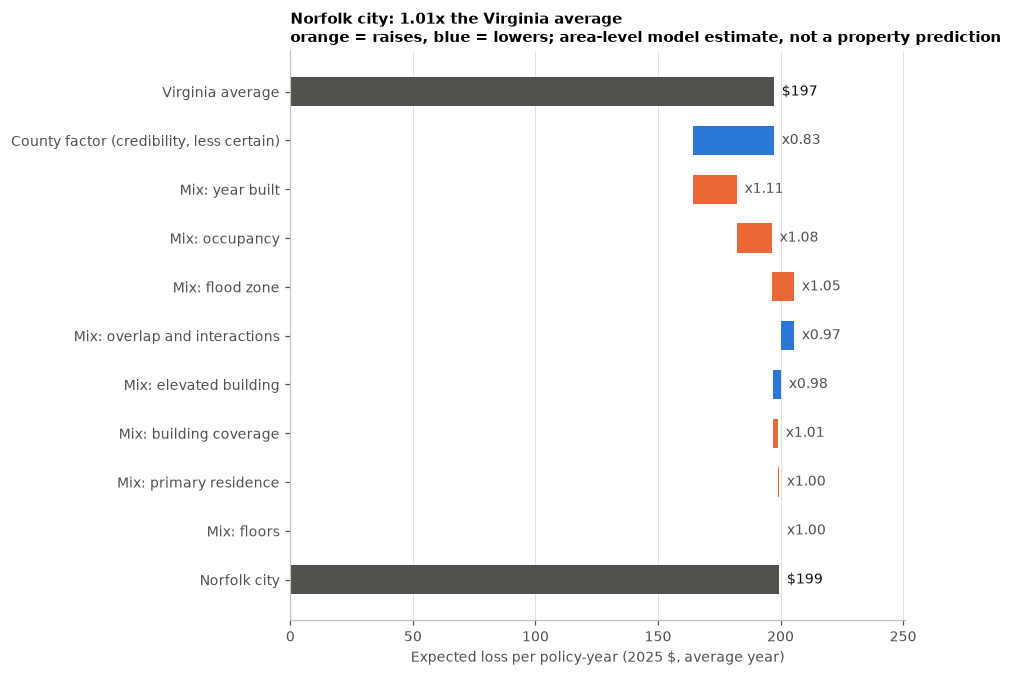

Model-based expected flood losses for insured buildings in Norfolk city are close to the Virginia average (about $199 vs $197 per policy-year in an average year): pushing it up, 68% of insured buildings here were built before 1980 (Virginia: 50%); pulling it down, its own claims history has had smaller claims than the model expects (county factor 0.83, high certainty). This is an area-level estimate, not a prediction for any individual property.
High certainty. The county factor (0.83) blends this county's own claim-size history (1,333 paid claims, credibility Z = 0.98) with the statewide model. There is plenty of local claim history, but county factors still move in storm years. Claim frequency gets no county credit anywhere (Z = 0): county differences in how often claims happen were no bigger than storm-to-storm noise. 



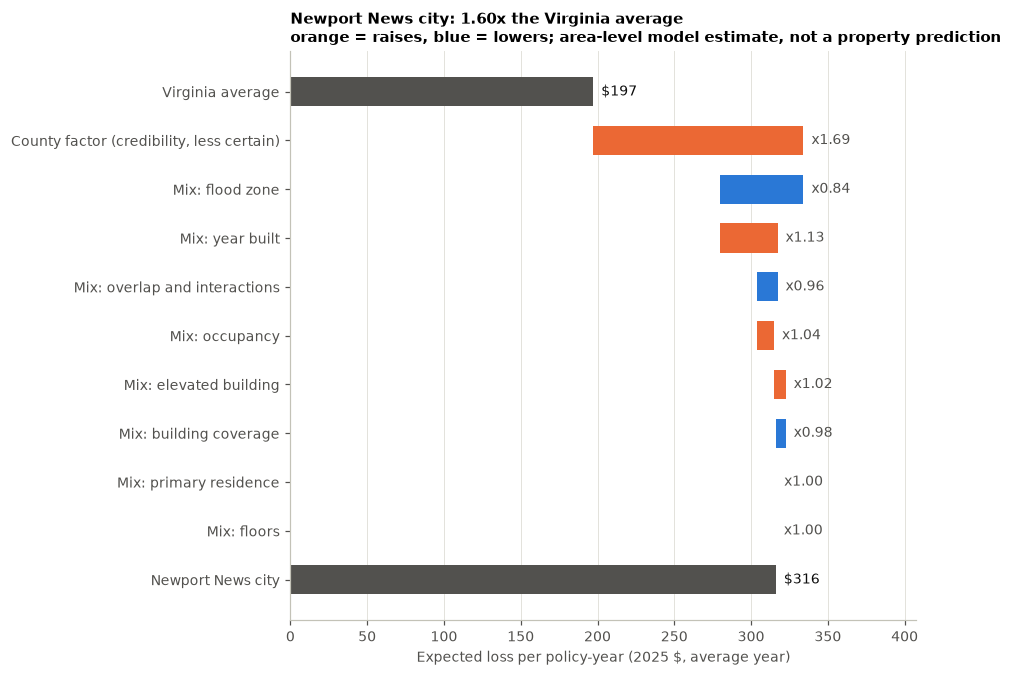

Model-based expected flood losses for insured buildings in Newport News city are about 1.6x the Virginia average (about $316 vs $197 per policy-year in an average year), mainly because its own claims history has had larger claims than the model expects (county factor 1.69, high certainty) and 60% of insured buildings here were built before 1980 (Virginia: 50%). This is an area-level estimate, not a prediction for any individual property.
High certainty. The county factor (1.69) blends this county's own claim-size history (339 paid claims, credibility Z = 0.91) with the statewide model. There is plenty of local claim history, but county factors still move in storm years. Claim frequency gets no county credit anywhere (Z = 0): county differences in how often claims happen were no bigger than storm-to-storm noise. 



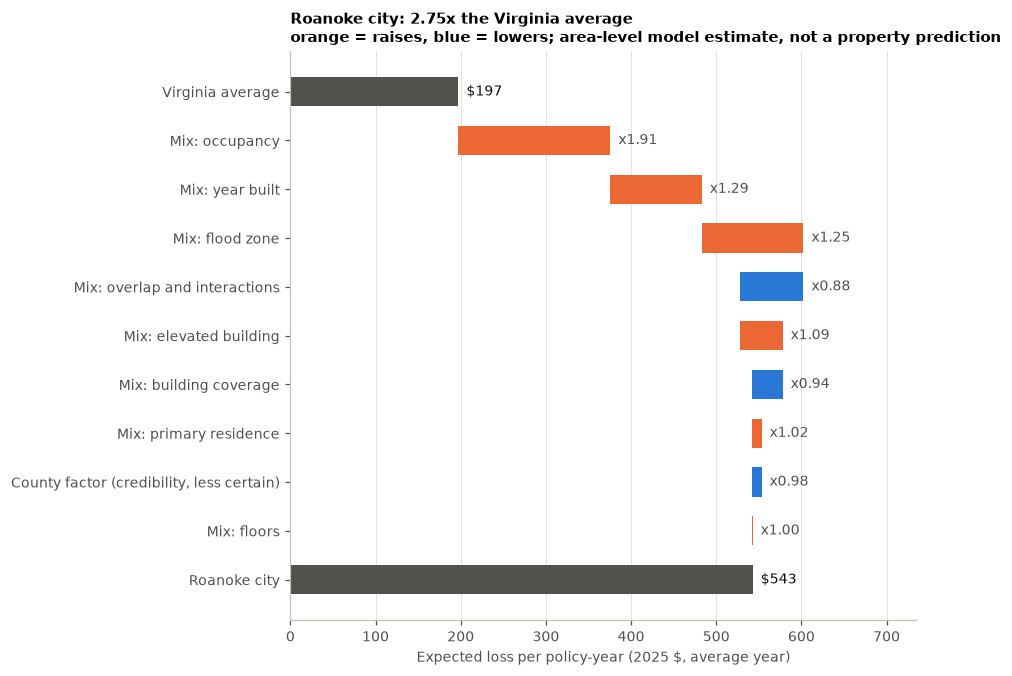

Model-based expected flood losses for insured buildings in Roanoke city are about 2.8x the Virginia average (about $543 vs $197 per policy-year in an average year), mainly because 46% of insured buildings here are multi-unit or non-residential buildings (Virginia: 11%) and 79% of insured buildings here were built before 1980 (Virginia: 50%). This is an area-level estimate, not a prediction for any individual property.
Medium certainty. The county factor (0.98) blends this county's own claim-size history (125 paid claims, credibility Z = 0.79) with the statewide model. There is some local evidence, but the factor is still uncertain. Claim frequency gets no county credit anywhere (Z = 0): county differences in how often claims happen were no bigger than storm-to-storm noise. 



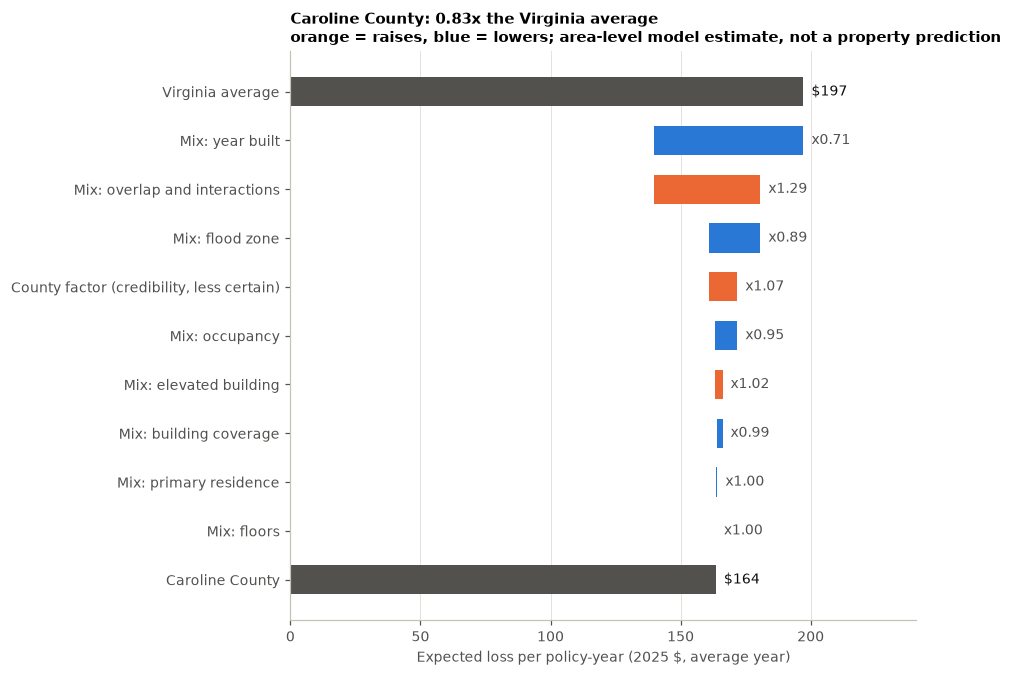

Model-based expected flood losses for insured buildings in Caroline County are about 17% below the Virginia average (about $164 vs $197 per policy-year in an average year), mainly because 29% of insured buildings here were built before 1980 (Virginia: 50%) and 39% of insured buildings here are in high-risk A/V zones (Virginia: 51%). This is an area-level estimate, not a prediction for any individual property.
Low certainty. The county factor (1.07) blends this county's own claim-size history (1 paid claims, credibility Z = 0.03) with the statewide model. With so few claims, most of the weight is on the statewide model and the factor could move a lot with one storm. Claim frequency gets no county credit anywhere (Z = 0): county differences in how often claims happen were no bigger than storm-to-storm noise. 



,county,pure_premium,ratio,mix_effect,county_factor_effect,county_factor,Z_sev,certainty,pct_av_zone
0,Norfolk city,199.321,1.011,1.213,0.833,0.833,0.976,High,55.927
1,Newport News city,316.112,1.603,0.946,1.694,1.693,0.911,High,33.391
2,Roanoke city,542.765,2.752,2.807,0.980,0.980,0.791,Medium,77.544
3,Caroline County,163.549,0.829,0.777,1.068,1.067,0.029,Low,39.185


In [20]:
CS = EX.county_summary
big = CS[CS["policy_years_2010_2025"] >= 1000]
low_z = big.sort_values("Z_sev").iloc[0]
COUNTIES = {"norfolk": "51710", "newport_news": "51700", "roanoke_city": "51770",
            "low_credibility_" + low_z["name"].split()[0].lower(): low_z["county"]}
CTY_ROWS = []
for slug, fips in COUNTIES.items():
    r = EX.explain_county(fips)
    E.plot_waterfall(r, FIG / f"10_waterfall_county_{slug}.png"); plt.show()
    print(r["sentence"]); print(r["uncertainty_note"], "\n")
    CTY_ROWS.append({"county": r["county_name"], "pure_premium": r["pure_premium"], "ratio": r["ratio_to_virginia"],
                     "mix_effect": r["mix_effect"], "county_factor_effect": r["county_factor_effect"],
                     "county_factor": r["county_factor"], "Z_sev": r["Z_sev"], "certainty": r["certainty"],
                     "pct_av_zone": r["mix"]["pct_av_zone"], "sentence": r["sentence"]})
pd.DataFrame(CTY_ROWS).to_csv(REP / "09_example_counties.csv", index=False)
pd.DataFrame(CTY_ROWS).drop(columns="sentence").round(3)

### All counties
`explain.explain_county` splits each county's ratio to Virginia exactly:
- **property mix:** what its insured buildings are like;
- **county factor:** its own credibility-weighted claims history.

The mix is then broken into one **mix index** per factor (the county's average multiplier ÷ Virginia's), plus an **overlap** step for interactions and for how factors combine.


**What the county breakdown shows:**
- **Property mix explains most of the differences between counties.** Exposure-weighted variance of log ratio: mix 0.129 vs county factor 0.042, with a small negative covariance. For 78% of the 32 large counties the mix step is bigger than the county-factor step.
- **The big coastal cities sit near the Virginia average for different reasons:**
  - Norfolk, Hampton and Portsmouth have risky mixes (old buildings, A/V zones) and county factors below 1.
  - Virginia Beach has a safer mix (36% A/V) but a factor of 1.21.
  - Newport News is 1.6× the average almost entirely because of its county factor (1.69).
- **The highest expected loss costs are small inland cities** (Bristol, Danville, Winchester, Staunton). That's the *mix*: 40–67% of their insured exposure is multi-unit or non-residential (Virginia: 11%), mostly in A/V zones, and those buildings have 2.8–4.6× bigger claims.
  - Their **actual** loss costs vary wildly: Bristol $52 from 3 claims, Danville $3,643.
  - Their county factors have **low or medium certainty**.
  - The app must show these as model-based estimates with the certainty label and the actual history side by side.
- **Overlap step:** median ×0.97. It's within ×0.8–1.25 for 83% of counties and 98% of exposure. It mostly reflects the coverage × occupancy interaction (correlation with the occupancy mix index −0.59): low-limit commercial buildings have smaller claims than the main effects suggest.

In [21]:
cols = ["name", "policy_years_2010_2025", "paid_claims_2010_2025", "actual_loss_cost_2010_2025", "expected_pure_premium",
        "ratio_to_virginia", "mix_effect", "county_factor_effect", "Z_sev", "certainty", "pct_av_zone", "pct_multi_or_nonres"]
print("Highest expected loss cost:"); print(CS[cols].head(8).round(2).to_string(index=False))
print("\nLargest 10 by insured policy-years:")
print(CS.sort_values("policy_years_2010_2025", ascending=False)[cols].head(10).round(2).to_string(index=False))
print("\nCertainty labels:", CS["certainty"].value_counts().to_dict(),
      f"| policy-years in High: {100 * CS.loc[CS.certainty == 'High', 'policy_years_2010_2025'].sum() / CS['policy_years_2010_2025'].sum():.0f}%")
o = np.log(CS["overlap_effect"]).abs()
print(f"Overlap step: median x{CS['overlap_effect'].median():.2f}; within x0.8-x1.25 for {100 * (o < math.log(1.25)).mean():.0f}% of counties "
      f"and {100 * CS.loc[o < math.log(1.25), 'policy_years_2010_2025'].sum() / CS['policy_years_2010_2025'].sum():.0f}% of exposure")
print(f"Correlation (log) between the overlap step and the occupancy mix index: "
      f"{np.corrcoef(np.log(CS['overlap_effect']), np.log(CS['mix_index_occupancy_group']))[0, 1]:.2f}")
w = CS["policy_years_2010_2025"]
print(f"Share of the log-variation in county ratios explained by mix vs county factor (exposure-weighted variance): "
      f"mix {float(np.cov(np.log(CS['mix_effect']), aweights=w)):.3f}, factor {float(np.cov(np.log(CS['county_factor_effect']), aweights=w)):.3f}")

Highest expected loss cost:
                name  policy_years_2010_2025  paid_claims_2010_2025  actual_loss_cost_2010_2025  expected_pure_premium  ratio_to_virginia  mix_effect  county_factor_effect  Z_sev certainty  pct_av_zone  pct_multi_or_nonres
        Bristol city                  920.35                      3                       51.57                 753.04               3.82        3.69                  1.03   0.08       Low        74.77                67.11
       Danville city                 1522.29                     81                     3642.73                 689.01               3.49        2.92                  1.20   0.71    Medium        64.85                55.76
      Halifax County                  446.10                     10                     3467.54                 685.68               3.48        2.33                  1.49   0.23       Low        71.75                51.97
      Pulaski County                 1621.87                     49             

## Summary
1. **Global drivers (production GLM):** year built and flood zone dominate (typical ×1.95 and ×1.63), then occupancy and the county factor. Floors barely matter.
2. **GLM vs XGBoost:** they agree on the top drivers, the size of geography and the two key interactions. They disagree where features overlap (post-FIRM vs year built) and where the GLM's storm-aware rule rejected small effects. XGBoost's frequency model gets elevation backwards for 76% of elevated exposure.
3. **Caveat:** explanations describe the model, not causes. Coverage stands in for building value, elevation is tangled with location, and year built stands in for pre-FIRM construction.
4. **Local:** `explain_profile` and `explain_county` give exact waterfalls from the Virginia average, plain-English sentences and certainty labels for all 133 Virginia localities (`app/data/`).

## Saved
- **Figures:** `reports/figures/10_*.png`.
- **Tables:** `reports/09_*.csv`.
- **App data:** `app/data/` (built by `src/explain.py build`; see `app/data/README.md`).
- **Write-up:** `reports/09_explainability.md`.